# Automated PCB Defect Detection Using Classical Image Processing Techniques

**Course:** ARTI 403 – Image Processing

**Group:** 2

**Team Members:**
- Sara Abdulaziz
- Sarah Khalid
- Dina Moteb
- Raghad Mohammed
- Hawra Habib
- Danah Eid

**Module:** Pipeline Integration

**Implemented by:** Sarah Khalid

This notebook integrates preprocessing, thresholding, and bounding box detection to identify potential PCB defects using DeepPCB images.

## 1. Setup and Image Loading

**Required modules:** preprocess.py, threshold.py, detection.py

**Dataset:** DeepPCB

The pipeline is tested using min_area=150 for integration verification. Final parameter selection requires validation on the training data.

In [4]:
import cv2
import matplotlib.pyplot as plt

# Download the dataset if needed
!test -d DeepPCB/PCBData || git clone https://github.com/tangsanli5201/DeepPCB.git

# Load the PCB image pair
test = cv2.imread("DeepPCB/PCBData/group00041/00041/00041000_test.jpg")
temp = cv2.imread("DeepPCB/PCBData/group00041/00041/00041000_temp.jpg")

if test is None or temp is None:
    raise FileNotFoundError("PCB images could not be loaded")

print("Test:", test.shape)
print("Template:", temp.shape)

Test: (640, 640, 3)
Template: (640, 640, 3)


## 2. Pipeline Implementation

In [5]:
%%writefile pipeline.py
from preprocess import difference
from threshold import make_mask
from detection import find_boxes

def run_pipeline(test, temp, min_area=100, pad=0):

    # Calculate the difference between images
    diff = difference(test, temp, blur="median", k=5)

    # Convert the difference into a binary mask
    mask = make_mask(diff, method="otsu")

    # Detect possible defect regions
    boxes = find_boxes(mask, min_area=min_area, pad=pad)

    return diff, mask, boxes

Writing pipeline.py


## 3. Pipeline Testing

In [6]:
from pipeline import run_pipeline

diff, mask, boxes = run_pipeline(
    test, temp, min_area=150, pad=0
)

print("Number of boxes:", len(boxes))
print("Detected boxes:", boxes)

Number of boxes: 2
Detected boxes: [(467, 317, 484, 382), (551, 271, 583, 304)]


## 4. Pipeline Visualization

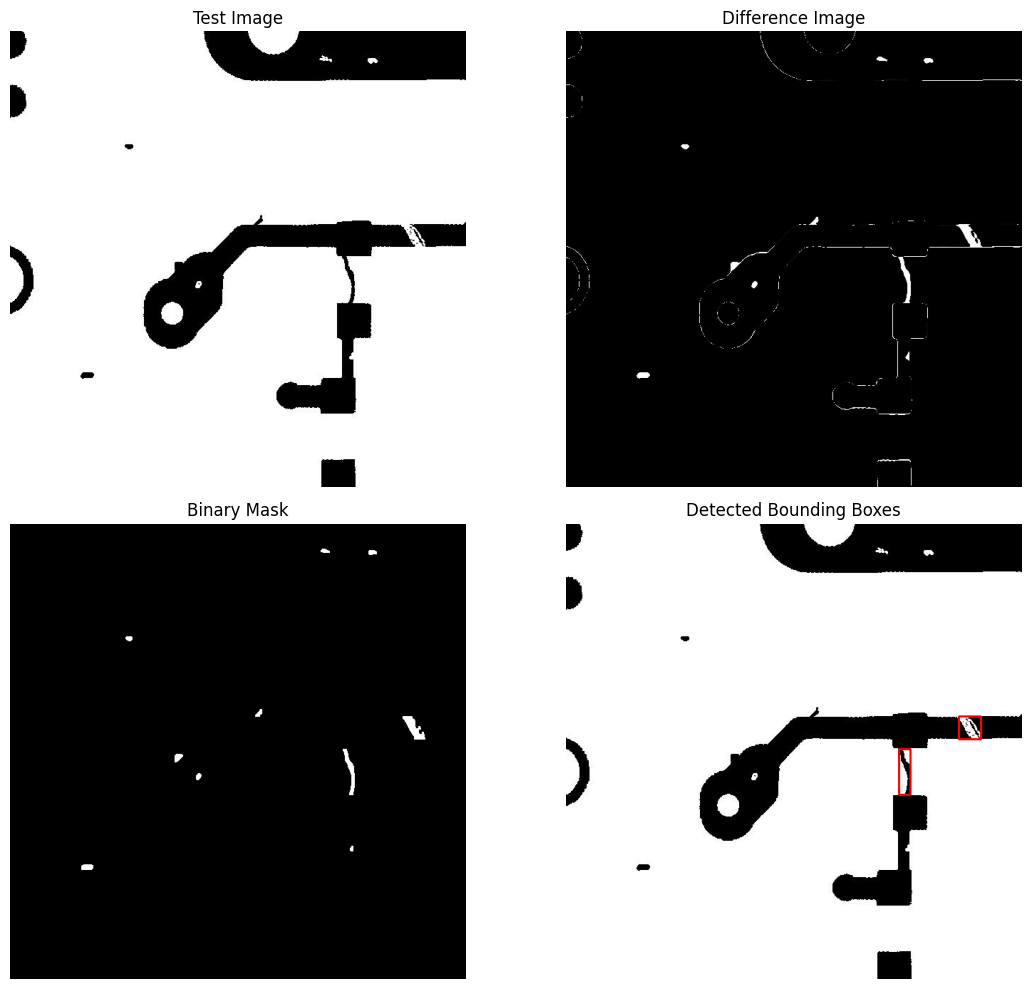

In [7]:
# Draw detected boxes on the test image
result = test.copy()

for x1, y1, x2, y2 in boxes:
    cv2.rectangle(
        result,
        (x1, y1),
        (x2 - 1, y2 - 1),
        (0, 0, 255),
        2
    )

# Display the pipeline stages
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(test, cv2.COLOR_BGR2RGB))
plt.title("Test Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(diff, cmap="gray")
plt.title("Difference Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(mask, cmap="gray")
plt.title("Binary Mask")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Detected Bounding Boxes")
plt.axis("off")

plt.tight_layout()
plt.show()